# Aperture Photometry Example

Following in part this series of tutorials by [Micah Laing](https://www.youtube.com/@mic_n_ike)
This uses the photulils package, which is part of astropy: https://photutils.readthedocs.io/en/stable/

1. [Astropy Lesson 1: Introduction to FITS File Handling](https://www.youtube.com/watch?v=_DzSIeruotQ) - I didn't do the start of this as using a different Jupyter Hub.
2. [Astropy Lesson 2: Photutils.detection](https://www.youtube.com/watch?v=vxMoG2K_n5o)
3. [Astropy Lesson 3: Aperture Photometry](https://www.youtube.com/watch?v=8162hq_5ZkQ) - didn't do the end as it's about calibration of HST images. 

I didn't need to install things because I did it on a [SciServer Astronomy](https://www.sciserver.org/) Compute Image. All the import statements also work on `python3.10.10` kernel on the Haverford Jupyter Hub (as of Nov 2024).

Last updated Oct 2026

- Karen Masters (for ASTR341 Class). 

First: 
1. Use AIJ to calibrate and align the two filters of images for your cluster (if using this for cluster photometry). 
Optional: You can WCS solve and then you can use SkyApertures. 
2. Don't forget to align the two median aligned images (you want the stars in the same pixel in both images to make the below easier)
3. Measure the size of a star in pixels (use AIJ to tell you the optimal aperture to use). You get a plot like this.
<img src="PerseusClusterData/Seeing_Profile_rband.png" width="300">

4. You then need to put the aligned calibrated fits images on the server you are running this code on....

I actually had three filters, so I made a three colour image of NGC844! The Double Cluster (h and χ Persei) is both NGC 869 and NGC 884, but only one fits in our CCD field of view at once. 

<img src="PerseusClusterData/RGB_NGC884.jpg" width="500">



In [42]:
import numpy as np

from astropy.io import fits

import matplotlib.pyplot as plt
from matplotlib.colors import LogNorm #Capitals matter

from astropy.stats import sigma_clipped_stats, SigmaClip

from photutils.detection import DAOStarFinder
from photutils.aperture import CircularAperture, CircularAnnulus
#from photoutils.aperture import AperturePhotometry #Only in later version of photutils
from photutils.aperture import aperture_photometry #I found that Aperture_photometry is now photometry. I can't get ApertureStars to load

from photutils.background import Background2D, MedianBackground


In [27]:
#Note the version of photutils matters. 
%pip show photutils

Name: photutils
Version: 1.2.0
Summary: An Astropy package for source detection and photometry
Home-page: https://github.com/astropy/photutils
Author: Photutils Developers
Author-email: photutils.team@gmail.com
License: BSD 3-Clause
Location: /home/idies/miniconda3/envs/py38/lib/python3.8/site-packages
Requires: astropy, numpy
Required-by: 
Note: you may need to restart the kernel to use updated packages.


In [66]:
fits_file = fits.open('PerseusClusterData/ngc884_MED_aligned_r.fits')
image_data=fits_file[0].data

In [68]:
#Remember this is just an array of numbers - one per pixel, with photon counts after flat field and bias subtraction
print(image_data)

[[  0.   0.   0. ...   0.   0.   0.]
 [ 88. 101. 103. ...  71.  80.   0.]
 [ 90. 114.  99. ...  68.  75.   0.]
 ...
 [101.  88.  84. ...  89.  64.   0.]
 [ 95.  98.  88. ...  91.  82.   0.]
 [ 89.  95.  87. ...   0.   0.   0.]]


In [69]:
#So you can do stats
print('Min: ', np.min(image_data))
print('Max: ', np.max(image_data))

Min:  0.0
Max:  44887.0


Text(0, 0.5, 'Number of pixels')

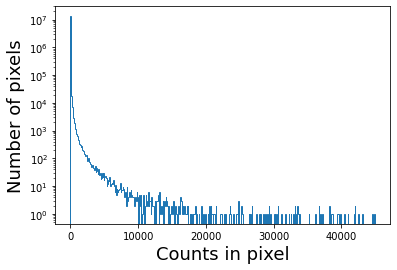

In [70]:
#Or plot a histogram. Easier to do this if you flatten the 2D array into a single array.
plt.hist(image_data.flatten(),histtype='step',bins=500)
plt.yscale('log')
plt.xlabel('Counts in pixel',fontsize=18)
plt.ylabel('Number of pixels',fontsize=18)

# Make an image
https://matplotlib.org/stable/api/_as_gen/matplotlib.pyplot.imshow.html

<function matplotlib.pyplot.show(close=None, block=None)>

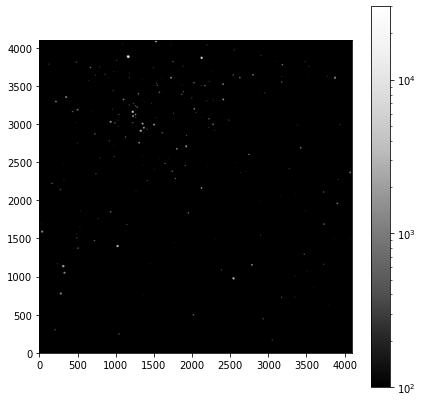

In [71]:
#You can make an image 
plt.figure(figsize=(7,7))
plt.imshow(image_data,origin='lower',norm=LogNorm(vmin=100,vmax=30000),cmap='Greys_r') #Greys_r inverts the scale
plt.colorbar()
plt.show

### You can select a section of the image

<function matplotlib.pyplot.show(close=None, block=None)>

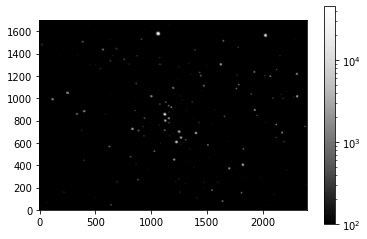

In [72]:
section1 = image_data[2300:4000, 100:2500]
plt.figure()
plt.imshow(section1,origin='lower',norm=LogNorm(vmin=100),cmap='Greys_r')
plt.colorbar()
plt.show

## Using DAO Star Finder

This can find all the point sources in your image. I did the entire image below. You could do just a section if your cluster is all in one part of the image. 

Sigma clip the data first to removes extreme outlier (saturatued pixels) and find the stars better. 

In [74]:
mean,median,std=sigma_clipped_stats(image_data,sigma=3.0)
print('Mean, Median, standard deviation (in counts):', mean,median,std)

Mean, Median, standard deviation (in counts): 84.548836 84.0 5.7956553


In [75]:
daofind=DAOStarFinder(fwhm=8.0,threshold=8.0*std) #FWHM = 7.96 is the measured value of our image
sources=daofind(image_data-median)

for col in sources.colnames:
    if col not in ('id','npix'):
        sources[col].info.format='%.2f'
        
sources.pprint(max_width=76)

 id xcentroid ycentroid sharpness roundness1 ... sky    peak   flux   mag 
--- --------- --------- --------- ---------- ... ---- ------- ------ -----
  1   3658.96      6.25      0.24       0.09 ... 0.00   55.00   2.74 -1.09
  2   4089.24      5.25      0.23      -0.25 ... 0.00    1.00   2.63 -1.05
  3     83.35     71.06      0.91      -0.51 ... 0.00   37.00   1.33 -0.31
  4   1550.53     92.21      0.32       0.20 ... 0.00   61.00   1.76 -0.62
  5   3108.77    139.29      0.52      -0.04 ... 0.00   68.00   1.57 -0.49
  6   2534.34    159.52      0.47      -0.32 ... 0.00   48.00   1.33 -0.31
  7   3051.34    169.94      0.35      -0.07 ... 0.00  318.00   7.73 -2.22
  8   1048.15    250.55      0.43       0.12 ... 0.00  500.00  12.45 -2.74
  9   1356.77    275.06      0.22      -0.06 ... 0.00   51.00   1.68 -0.56
 10   3752.37    291.49      0.62       0.16 ... 0.00   71.00   1.47 -0.41
...       ...       ...       ...        ... ...  ...     ...    ...   ...
551   1725.08   4028.81  

### Overlay Apertures on Detected Stars

In [76]:
positions=np.transpose((sources['xcentroid'],sources['ycentroid'])) #Because python does yx.
apertures = CircularAperture(positions,r=15.0) # This is the 1.5 FWHM as measured from the image using AIJ

<function matplotlib.pyplot.show(close=None, block=None)>

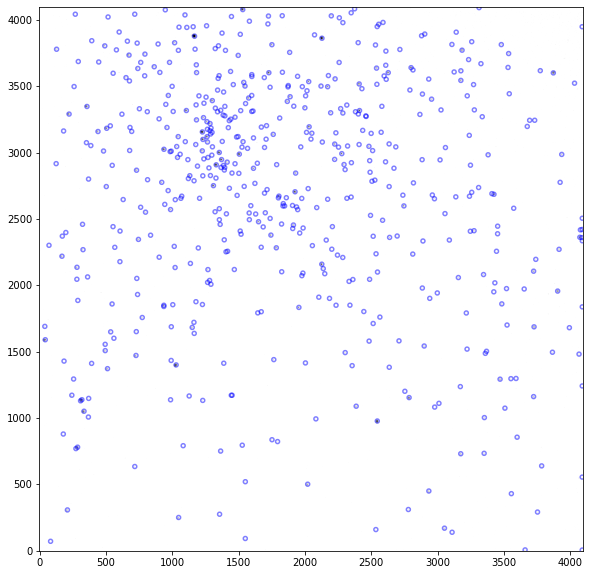

In [77]:
plt.figure(figsize=(10,10))
plt.imshow(image_data,origin='lower',norm=LogNorm(vmin=100,vmax=20000),cmap='Greys',interpolation = 'nearest')
apertures.plot(color='blue',lw=1.5,alpha=0.5);

#plt.colorbar()
plt.show

# Aperture Photometry

Goal here it to make a sky aperture around each star to subtract the background. 

## Making an Annulus for the Background

First step is easy - just using the radii recommended by AIJ

In [78]:
annulus_aperture = CircularAnnulus(positions, r_in=27, r_out=41) # Set these to the ideal innder and outer apertures. 

<function matplotlib.pyplot.show(close=None, block=None)>

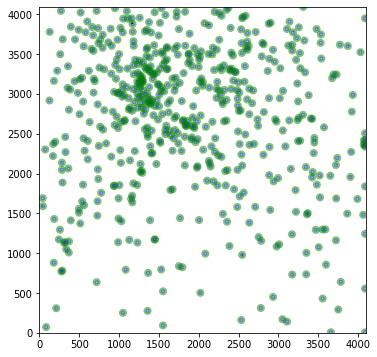

In [79]:
plt.figure(figsize=(10,6))
plt.imshow(image_data,origin='lower',norm=LogNorm(vmin=100,vmax=30000),cmap='Greys',interpolation = 'nearest')
apertures.plot(color='blue',lw=1.5,alpha=0.5);
annulus_aperture.plot(color='green',lw=1.5,alpha=0.5)
#plt.colorbar()
plt.show

In [80]:
star_data = aperture_photometry(image_data,apertures)

In [81]:
bkg = aperture_photometry(image_data,annulus_aperture)
bkg_area = annulus_aperture.area_overlap(image_data)
aperture_area = apertures.area_overlap(image_data)
bkg_total = (bkg['aperture_sum']/bkg_area)*aperture_area #deals with different sizes of the apertures

In [82]:
star_data['total_bkg']=bkg_total
star_data['bkg_area']=bkg_area
star_data['aperture_area']=aperture_area
star_data['star_count']=star_data['aperture_sum']-star_data['total_bkg']


for col in star_data.colnames:
    star_data[col].info.format='%.8g'

star_data.pprint

<bound method Table.pprint of <QTable length=561>
  id   xcenter   ycenter  aperture_sum ...  bkg_area aperture_area star_count
         pix       pix                 ...                                   
int64  float64   float64    float64    ...  float64     float64     float64  
----- --------- --------- ------------ ... --------- ------------- ----------
    1 3658.9589 6.2544444    55660.814 ... 1685.8478     548.98958  10013.088
    2 4089.2432 5.2498358    29776.489 ... 916.72337      387.8306 -2113.9574
    3 83.348758 71.055197    60638.439 ... 2990.7962     706.85835  628.81769
    4 1550.5268 92.209747    70341.934 ... 2990.7962     706.85835  11838.355
    5 3108.7685 139.29281    71056.112 ... 2990.7962     706.85835  11488.644
    6 2534.3431 159.51657    66785.342 ... 2990.7962     706.85835   7203.566
    7 3051.3407 169.94259    119354.88 ... 2990.7962     706.85835  59446.302
    8 1048.1541 250.55467    147089.98 ... 2990.7962     706.85835  88811.015
    9 1356.765

### Raw Instrumental Magnitudes of Sources and Background. 

Background done this way has stars in it - not ideal. 

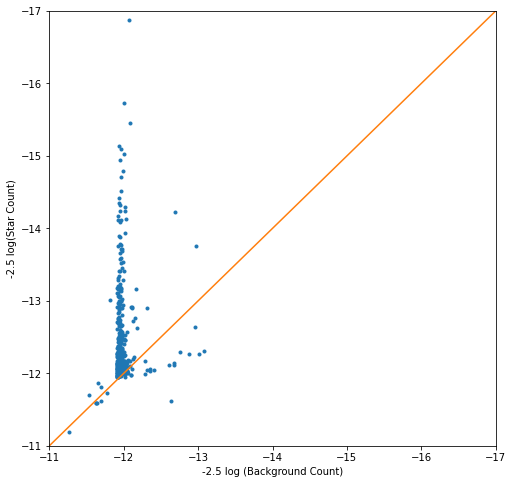

In [83]:
plt.figure(figsize=(8,8))
plt.plot(-2.5*np.log10(star_data['total_bkg']),-2.5*np.log10(star_data['aperture_sum']),'.')
plt.plot([-17,-11],[-17,-11])
plt.ylim(-11,-17)
plt.xlim(-11,-17)
plt.ylabel('-2.5 log(Star Count)')
plt.xlabel('-2.5 log (Background Count)')
plt.show()


### A Better Background

Photutils has techniques to estimate background. https://photutils.readthedocs.io/en/stable/user_guide/background.html#

In [84]:
#Text from the photutils background page: 
#We start by creating a Background2D object using a box size of 15x15 and a 3x3 median filter. 
#We will estimate the background level in each mesh as the sigma-clipped median using an instance of 
#MedianBackground:
#KLM edits - when I did this the background had obvious stars in it. I made the box size larger, 
# and sigmaclip lower to remove more
sigma_clip = SigmaClip(sigma=2.0)
bkg_estimator = MedianBackground()
bkg = Background2D(image_data, (30, 30), filter_size=(6, 6),
                   sigma_clip=sigma_clip, bkg_estimator=bkg_estimator)

In [85]:
#vThe global median value of the low-resolution background and background RMS image can be accessed with 
# the background_median and background_rms_median attributes, respectively:
print(bkg.background_median)

84.10422704644839


In [86]:
print(round(bkg.background_rms_median, 4))

4.382


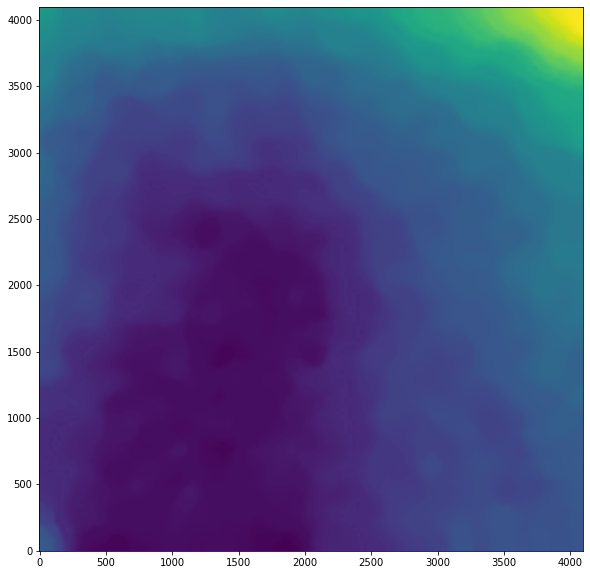

In [87]:
# Plot the background
fig, ax = plt.subplots(figsize=(10,10))
ax.imshow(bkg.background, origin='lower')

In [88]:
#Now just use the star apertures to measure background on the background image
#star_data = aperture_photometry(image_data,apertures)
bkg2 = aperture_photometry(bkg.background,apertures)

In [89]:
star_data['better_bkg']=bkg2['aperture_sum']
star_data['better_star_count']=star_data['aperture_sum']-star_data['better_bkg']

for col in star_data.colnames:
    star_data[col].info.format='%.8g'

star_data.pprint

<bound method Table.pprint of <QTable length=561>
  id   xcenter   ycenter  ... star_count better_bkg better_star_count
         pix       pix    ...                                        
int64  float64   float64  ...  float64    float64        float64     
----- --------- --------- ... ---------- ---------- -----------------
    1 3658.9589 6.2544444 ...  10013.088  46473.839         9186.9744
    2 4089.2432 5.2498358 ... -2113.9574  32906.654        -3130.1652
    3 83.348758 71.055197 ...  628.81769  59895.161         743.27863
    4 1550.5268 92.209747 ...  11838.355  57889.335         12452.599
    5 3108.7685 139.29281 ...  11488.644  59778.288         11277.825
    6 2534.3431 159.51657 ...   7203.566   58811.01         7974.3316
    7 3051.3407 169.94259 ...  59446.302  59581.694         59773.183
    8 1048.1541 250.55467 ...  88811.015  58075.384         89014.599
    9 1356.7658   275.057 ...  9867.8756  57962.235          9993.606
  ...       ...       ... ...        ...

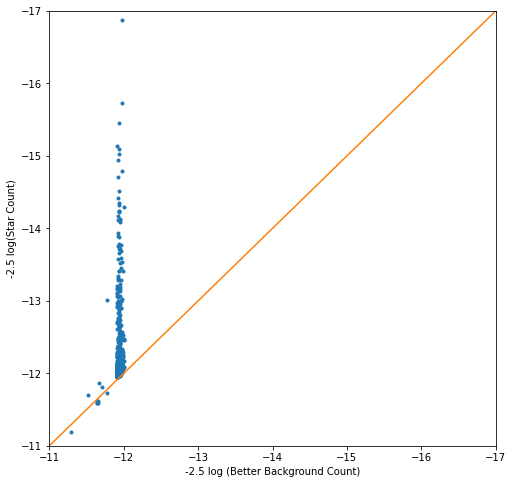

In [90]:
plt.figure(figsize=(8,8))
plt.plot(-2.5*np.log10(star_data['better_bkg']),-2.5*np.log10(star_data['aperture_sum']),'.')
plt.plot([-17,-11],[-17,-11])
plt.ylim(-11,-17)
plt.xlim(-11,-17)
plt.ylabel('-2.5 log(Star Count)')
plt.xlabel('-2.5 log (Better Background Count)')
plt.show()

### Instrumental Magnitudes

These are just -2.5 log10 (counts)

You can't do it for when the background is greater than the star flux - so quick method is to just ignore those. 

In [91]:
star_data_good=star_data[(star_data['better_star_count']>0)]
star_data_good['inst_mag_r']=-2.5*np.log10(star_data_good['better_star_count'])

star_data_good

id,xcenter,ycenter,aperture_sum,total_bkg,bkg_area,aperture_area,star_count,better_bkg,better_star_count,inst_mag_r
,pix,pix,,,,,,,,
int64,float64,float64,float64,float64,float64,float64,float64,float64,float64,float64
1,3658.9589,6.2544444,55660.814,45647.726,1685.8478,548.98958,10013.088,46473.839,9186.9744,-9.9079313
3,83.348758,71.055197,60638.439,60009.622,2990.7962,706.85835,628.81769,59895.161,743.27863,-7.1778791
4,1550.5268,92.209747,70341.934,58503.58,2990.7962,706.85835,11838.355,57889.335,12452.599,-10.23815
5,3108.7685,139.29281,71056.112,59567.468,2990.7962,706.85835,11488.644,59778.288,11277.825,-10.130563
6,2534.3431,159.51657,66785.342,59581.776,2990.7962,706.85835,7203.566,58811.01,7974.3316,-9.7542357
7,3051.3407,169.94259,119354.88,59908.574,2990.7962,706.85835,59446.302,59581.694,59773.183,-11.941266
8,1048.1541,250.55467,147089.98,58278.968,2990.7962,706.85835,88811.015,58075.384,89014.599,-12.373653
9,1356.7658,275.057,67955.841,58087.965,2990.7962,706.85835,9867.8756,57962.235,9993.606,-9.9993056


# Do the second filter

Now do the same stuff for the second filter. I'll do g-band. 

You should check the seeing FWHM in this filter, but really should use the same apertures for both filters. Ill use the r-band one. They are about the same. 

<img src="PerseusClusterData/Seeing_Profile_gband.png" width="300">


In [94]:
fits_file = fits.open('PerseusClusterData/ngc884_MED_aligned_g.fits')
image_data=fits_file[0].data

In [95]:
apertures_g = CircularAperture(positions,r=15.0) # This is the 1.5 FWHM as measured from the image using AIJ

<function matplotlib.pyplot.show(close=None, block=None)>

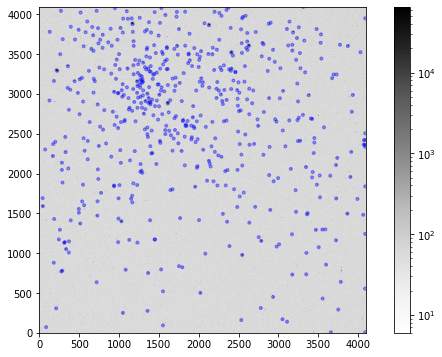

In [96]:
plt.figure(figsize=(10,6))
plt.imshow(image_data,origin='lower',norm=LogNorm(),cmap='Greys',interpolation = 'nearest')
apertures_g.plot(color='blue',lw=1.5,alpha=0.5);
plt.colorbar()
plt.show

In [97]:
star_data_g = aperture_photometry(image_data,apertures_g)

In [98]:
sigma_clip = SigmaClip(sigma=2.0)
bkg_estimator = MedianBackground()
bkg = Background2D(image_data, (30, 30), filter_size=(6, 6),
                   sigma_clip=sigma_clip, bkg_estimator=bkg_estimator)

In [99]:
print(bkg.background_median)
print(round(bkg.background_rms_median, 4))

59.12624045255831
4.1039


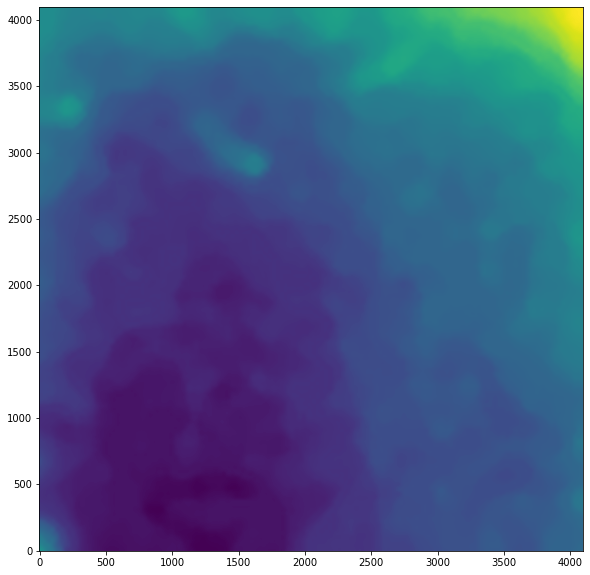

In [100]:
# Plot the background
fig, ax = plt.subplots(figsize=(10,10))
ax.imshow(bkg.background, origin='lower')


In [101]:
bkg2 = aperture_photometry(bkg.background,apertures)

star_data['better_bkg_g']=bkg2['aperture_sum']
star_data['better_star_count_g']=star_data_g['aperture_sum']-star_data['better_bkg_g']

for col in star_data.colnames:
    star_data[col].info.format='%.8g'

star_data.pprint

<bound method Table.pprint of <QTable length=561>
  id   xcenter   ycenter  ... better_star_count better_bkg_g better_star_count_g
         pix       pix    ...                                                   
int64  float64   float64  ...      float64        float64          float64      
----- --------- --------- ... ----------------- ------------ -------------------
    1 3658.9589 6.2544444 ...         9186.9744    32470.192           108663.81
    2 4089.2432 5.2498358 ...        -3130.1652    23301.421          -5800.2673
    3 83.348758 71.055197 ...         743.27863    42653.205           910.63126
    4 1550.5268 92.209747 ...         12452.599    40294.534           16153.504
    5 3108.7685 139.29281 ...         11277.825    41780.421           16529.813
    6 2534.3431 159.51657 ...         7974.3316    41157.313           12722.697
    7 3051.3407 169.94259 ...         59773.183    41772.547           76884.752
    8 1048.1541 250.55467 ...         89014.599    40146.26

In [102]:
#Do both instrumental magnitudes

star_data_good=star_data[(star_data['better_star_count']>0) & (star_data['better_star_count_g']>0)]
star_data_good['inst_mag_r']=-2.5*np.log10(star_data_good['better_star_count'])
star_data_good['inst_mag_g']=-2.5*np.log10(star_data_good['better_star_count_g'])

star_data_good.pprint

<bound method Table.pprint of <QTable length=554>
  id   xcenter   ycenter  ... better_star_count_g inst_mag_r inst_mag_g
         pix       pix    ...                                          
int64  float64   float64  ...       float64        float64    float64  
----- --------- --------- ... ------------------- ---------- ----------
    1 3658.9589 6.2544444 ...           108663.81 -9.9079313 -12.590212
    3 83.348758 71.055197 ...           910.63126 -7.1778791 -7.3983564
    4 1550.5268 92.209747 ...           16153.504  -10.23815 -10.520667
    5 3108.7685 139.29281 ...           16529.813 -10.130563  -10.54567
    6 2534.3431 159.51657 ...           12722.697 -9.7542357 -10.261448
    7 3051.3407 169.94259 ...           76884.752 -11.941266 -12.214601
    8 1048.1541 250.55467 ...           147829.16 -12.373653   -12.9244
    9 1356.7658   275.057 ...           28035.309 -9.9993056 -11.119263
   10 3752.3712 291.49423 ...           39454.087 -10.164995  -11.49023
  ...       ..

# Colour Magnitude Diagram

(-8.0, -16.0)

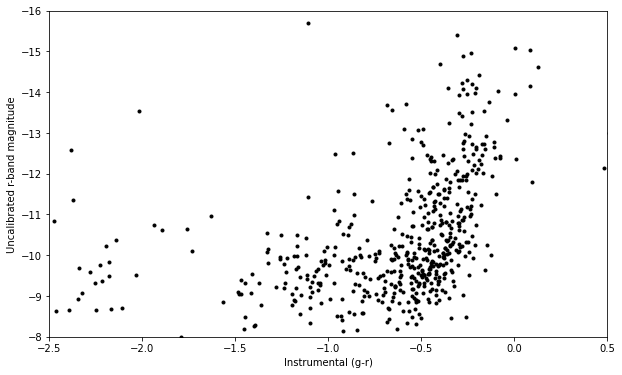

In [103]:
r = star_data_good['inst_mag_r']
grcolor = star_data_good['inst_mag_g'] - star_data_good['inst_mag_r']

plt.figure(figsize=(10,6))
plt.plot(grcolor, r, '.k')
plt.xlabel ('Instrumental (g-r)')
plt.ylabel ('Uncalibrated r-band magnitude')
plt.xlim(-2.5,0.5)
plt.ylim(-8,-16)
